# Individual homework project 1

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [21]:
import os

print("I am here:", os.getcwd())
print("\nFiles in this folder:")
print(os.listdir())

print("\n--- Searching Documents ---")
for root, dirs, files in os.walk(r"C:\Users\user\Documents"):
    if "customers.csv" in files:
        print("FOUND customers.csv in:", root)

I am here: c:\Users\user\Documents

Files in this folder:
['AI Chat and Workshop Certificate (27).pdf', 'Certificate of   Recognition.pdf', 'Crazy Rich Asians - A Novel by Kevin Kwan.pdf', 'Custom Office Templates', 'Data', 'desktop.ini', 'Document (5)[1].docx', 'draft.docx', 'Electronic Arts', 'Exam_Notes__Final_.pdf', 'Exam_Preparation.docx.pdf', 'finance tracker.xlsx', 'hw_1_project.ipynb', 'Introduction.docx', 'life orientation.docx', 'Limitations WVES 1st draft .pdf', 'modules passed.jpeg', 'My Music', 'My Pictures', 'My Videos', 'NeoDitlopAdminCV.docx', 'NeoDitlopCV3.docx', 'NeoDitlopoSecurity.docx', 'notes usvs rand.docx', 'Project%20Template.docx_0.odt', 'Project%20Template.docx_0_1.odt', 'Project%20Template.docx_0_2.odt', 'researcg deck.docx', 'Textbook Public Economics Econ314.pdf', 'understanding Business and Ethics.pdf', 'Untitled Diagram.drawio', 'Untitled Diagram.drawio.png', 'WhatsApp Image 2024-08-07 at 12.35.17_583c6a1d.jpg', 'WhatsApp Image 2024-08-07 at 12.35.18_2cfe

In [22]:
import pandas as pd

#path to files
base = r"C:\Users\user\Documents\Data"

customers = pd.read_csv(base + r"\customers.csv", low_memory=False)
print("Customers loaded:", customers.shape)

transactions = pd.read_csv(base + r"\transactions.csv", low_memory=False)
print("Transactions loaded:", transactions.shape)

df = transactions.merge(customers, on="customer_id", how="left")
df["purchase_date"] = pd.to_datetime(df["purchase_date"])
df["year"] = df["purchase_date"].dt.year

print("Merged:", df.shape)
df.head()

Customers loaded: (10000, 10)
Transactions loaded: (45000, 9)
Merged: (45000, 19)


,transaction_id,customer_id,product_category,purchase_value,discount_used,purchase_date,is_refunded,refund_date,refund_reason,age,gender,country,acquisition_channel,signup_date,customer_status,loyalty_tier,campaign_id,last_active_date,year
0,1,8141,home,380.95,0,2023-09-05,0,NaN,NaN,39.0,Male,UK,social,2021-04-13,one_time,none,463,2023-04-19,2023
1,2,1297,fashion,67.08,0,2019-08-07,0,NaN,NaN,43.0,Female,Spain,email,2024-03-10,one_time,none,725,2024-06-27,2019
2,3,7930,toys,43.37,1,2020-02-07,1,1.581898e+18,late_delivery,19.0,Male,Netherlands,referral,2022-11-28,one_time,none,285,2024-09-20,2020
3,4,2426,electronics,1191.45,0,2020-10-02,0,NaN,NaN,67.0,Female,Australia,referral,2023-09-14,vip,gold,567,2024-07-09,2020
4,5,6614,fashion,112.21,0,2023-09-15,0,NaN,NaN,50.0,Other,Germany,paid_search,2021-10-20,one_time,none,780,2024-04-24,2023


### Specific questions

Q1. What is the average purchase value for customers from Spain?

In [23]:
spain_avg = df.loc[df["country"] == "Spain", "purchase_value"].mean()
print(f"Q1. Average purchase value (Spain): {spain_avg:,.2f}")


Q1. Average purchase value (Spain): 230.96


Q2. What is the minimum purchase value for customers from Germany?

In [24]:
germany_min = df.loc[df["country"] == "Germany", "purchase_value"].min()
print(f"Q2. Minimum purchase value (Germany): {germany_min:,.2f}")

Q2. Minimum purchase value (Germany): 10.01


Q3. How much did males spend on buying products in the Sports category?

In [25]:
male_sports = df.loc[(df["gender"] == "Male") & (df["product_category"] == "sports"), "purchase_value"].sum()
print(f"Q3. Total spent by males on Sports: {male_sports:,.2f}")


Q3. Total spent by males on Sports: 404,877.87


Q4. What is the average age of female customers from Canada?

In [26]:
canada_f_age = customers.loc[(customers["gender"] == "Female") & (customers["country"] == "Canada"), "age"].mean()
print(f"Q4. Average age of female customers from Canada:{canada_f_age:.1f}")

Q4. Average age of female customers from Canada:42.9


Q5. How much does an average male customer from the UK spend?

In [27]:

uk_male = df[(df["gender"] == "Male") & (df["country"] == "UK")] 
per_customer = uk_male.groupby("customer_id")["purchase_value"].sum()
print(f"Q5. Average total spend per UK male customer:{per_customer.mean():,.2F}")
print(f" (Average single purchase by Uk males:{uk_male['purchase_value'].mean():,.2f})")

Q5. Average total spend per UK male customer:1,051.55
 (Average single purchase by Uk males:234.48)


Q6. What is the maximum purchase value for females in the Toys category?

In [28]:

print("Categories:", df["product_category"].unique()[:10])

f_toys_max = df.loc[(df["gender"] == "Female") & (df["product_category"].str.lower() == "toys"), "purchase_value"].max()

print(f"Q6. Maximum purchase value (females, Toys): {f_toys_max:.2f}")

Categories: ['home' 'fashion' 'toys' 'electronics' 'sports' 'beauty']
Q6. Maximum purchase value (females, Toys): 79.99


Q7. What is the average number of pages viewed for customers who made a purchase (converted)?

In [29]:
print ("transactions columns:", list(transactions.columns))
print("customers columns:", list(customers.columns))
print("Pages viewed:", any("page" in c.lower () for c in df.columns))

transactions columns: ['transaction_id', 'customer_id', 'product_category', 'purchase_value', 'discount_used', 'purchase_date', 'is_refunded', 'refund_date', 'refund_reason']
customers columns: ['customer_id', 'age', 'gender', 'country', 'acquisition_channel', 'signup_date', 'customer_status', 'loyalty_tier', 'campaign_id', 'last_active_date']
Pages viewed: False


Q8. What is the average time spent on the site for purchasing vs non-purchasing customers?

In [30]:
print("Time on site:", any(k in c.lower() for c in df.columns for k in ["time", "duration", "session"]
                           if c not in ("signup_date", "last_active", "purchase_date", "refund_date")))

Time on site: False


### Visualisation tasks

Q9. Plot purchasing value across years.

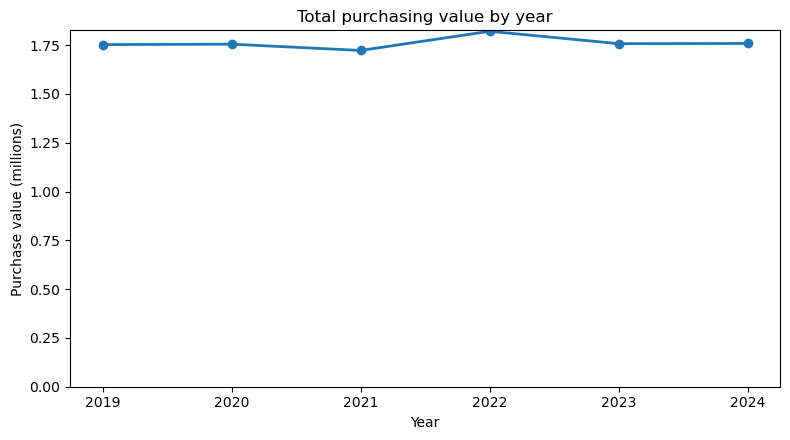

year
2019    1753046.60
2020    1755373.82
2021    1723096.74
2022    1821268.82
2023    1757793.75
2024    1758932.53
Name: purchase_value, dtype: float64

In [31]:

by_year = df.groupby("year")["purchase_value"].sum()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(by_year.index, by_year.values / 1e6, marker="o", linewidth=2)
ax.set_title("Total purchasing value by year")
ax.set_xlabel("Year")
ax.set_ylabel("Purchase value (millions)")
ax.set_ylim(0)
plt.tight_layout()
plt.show()
by_year

Q10. Plot purchasing value across product categories.

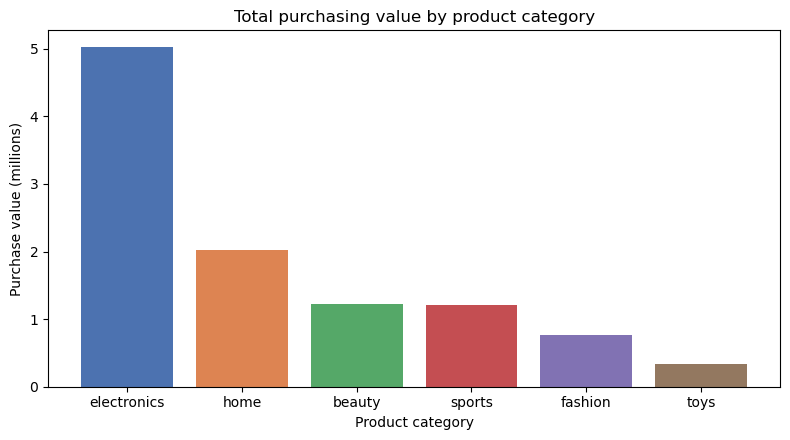

product_category
electronics    5020188.13
home           2022597.38
beauty         1218918.23
sports         1210881.70
fashion         759966.11
toys            336960.71
Name: purchase_value, dtype: float64

In [32]:

by_cat = df.groupby("product_category")["purchase_value"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(by_cat.index, by_cat.values / 1e6, color=sns.color_palette("deep", len(by_cat)))
ax.set_title("Total purchasing value by product category")
ax.set_xlabel("Product category")
ax.set_ylabel("Purchase value (millions)")
plt.tight_layout()
plt.show()
by_cat

### Free exercise

Explore the transactions dataset and:

- Create two visualisations of your choice
- Identify three patterns in the data
- Write five insights in plain English explaining what the data tells us

Your insights should focus on behaviour, spending patterns, or conversion

                    revenue  orders  avg_value  revenue_share_%  \
product_category                                                  
electronics       5020188.1    7424      676.2             47.5   
home              2022597.4    7488      270.1             19.1   
beauty            1218918.2    7586      160.7             11.5   
sports            1210881.7    7504      161.4             11.5   
fashion            759966.1    7581      100.2              7.2   
toys               336960.7    7417       45.4              3.2   

                  orders_share_%  
product_category                  
electronics                 16.5  
home                        16.6  
beauty                      16.9  
sports                      16.7  
fashion                     16.8  
toys                        16.5  


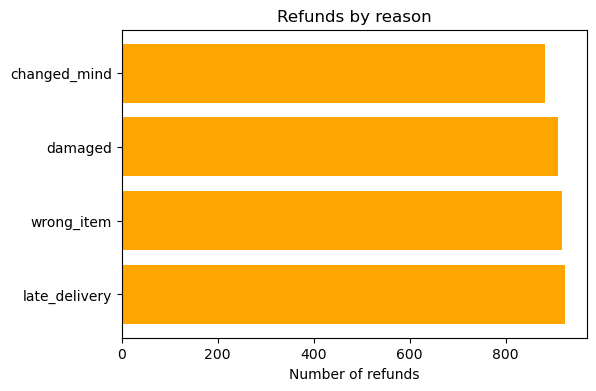

Pattern 1 - revenue by category
product_category
electronics    5020188.13
home           2022597.38
beauty         1218918.23
sports         1210881.70
fashion         759966.11
toys            336960.71
Name: purchase_value, dtype: float64
product_category
beauty         160.7
electronics    676.2
fashion        100.2
home           270.1
sports         161.4
toys            45.4
Name: purchase_value, dtype: float64
Pattern 2 - discount vs no discount
discount_used
0    234.6
1    235.6
Name: purchase_value, dtype: float64
discount_used
0    0.081
1    0.080
Name: is_refunded, dtype: float64
Pattern 3a - by year
year
2019    232.4
2020    233.1
2021    232.8
2022    240.7
2023    235.3
2024    235.0
Name: purchase_value, dtype: float64

Pattern 3b - by gender
gender
Female    235.9
Male      234.8
Other     233.8
Name: purchase_value, dtype: float64

Pattern 3c - by country
country
Australia      232.4
Canada         232.8
France         237.2
Germany        239.0
Netherlands    237.

In [33]:


#visual 1: Table
cat = df.groupby("product_category")["purchase_value"].agg(["sum", "count", "mean"])
cat = cat.rename(columns={"sum":"revenue", "count":"orders", "mean":"avg_value"})
cat = cat.sort_values("revenue", ascending=False)
cat["revenue_share_%"] = cat["revenue"] / cat["revenue"].sum() * 100
cat["orders_share_%"] = cat["orders"] / cat["orders"].sum() * 100

print(cat.round(1))

#visual 2: graph 
reasons = df["refund_reason"].value_counts()

plt.figure(figsize=(6,4))
plt.barh(reasons.index, reasons.values, color="orange")
plt.title("Refunds by reason")
plt.xlabel("Number of refunds")
plt.show()












#  Pattern 1

print("Pattern 1 - revenue by category")
print(df.groupby("product_category")["purchase_value"].sum().sort_values(ascending=False))
print(df.groupby("product_category")["purchase_value"].mean().round(1))

#Pattern 2
print("Pattern 2 - discount vs no discount")
print(df.groupby("discount_used")["purchase_value"].mean().round(1))
print(df.groupby("discount_used")["is_refunded"].mean().round(3))

#pattern 3

print("Pattern 3a - by year")
print(df.groupby("year")["purchase_value"].mean().round(1))

print("\nPattern 3b - by gender")
print(df.groupby("gender")["purchase_value"].mean().round(1))

print("\nPattern 3c - by country")
print(df.groupby("country")["purchase_value"].mean().round(1))